Лабораторна робота № 4

![Alt text](img.jpg)


Студента групи КН-315

Лозового О.А.


![Alt text](img.jpg)


Студента групи КН-315

Лозового О.А.

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [2]:
def run(episodes, is_training=False, render=False, save_to='mountain_car', read_from='mountain_car'):
 
    env = gym.make('MountainCar-v0', render_mode='human' if render else None)
 
    pos_space = np.linspace(env.observation_space.low[0], env.observation_space.high[0], 20)    # -1.2 to 0.6
    vel_space = np.linspace(env.observation_space.low[1], env.observation_space.high[1], 20)    # -0.07 to 0.07
 
    if(is_training):
        q = np.zeros((len(pos_space), len(vel_space), env.action_space.n)) # 20x20x3
    else:
        print(f'/Users/davemag9/VSCode/Machine Learning/lab3/{read_from}.pkl')
        f = open(f'/Users/davemag9/VSCode/Machine Learning/lab3/{read_from}.pkl', 'rb')
        q = pickle.load(f)
        f.close()
 
    learning_rate_a = 0.9 # learning rate
    discount_factor_g = 0.9 # discount factor.
 
    epsilon = 1
    epsilon_decay_rate = 2/episodes
    rng = np.random.default_rng()
 
    rewards_per_episode = np.zeros(episodes)
    successes = 0
 
    for i in range(episodes):
        if i % 100 == 0 and episodes > 100:
            print(str(i / episodes * 100) + '%')

        state = env.reset()[0]
        state_p = np.digitize(state[0], pos_space)
        state_v = np.digitize(state[1], vel_space)
 
        terminated = False
        rewards=0
 
        while(not terminated and rewards>-1000):
 
            if is_training and rng.random() < epsilon:
                # (0=drive left, 1=stay neutral, 2=drive right)
                action = env.action_space.sample()
            else:
                action = np.argmax(q[state_p, state_v, :])
 
            new_state,reward,terminated,_,_ = env.step(action)
            new_state_p = np.digitize(new_state[0], pos_space)
            new_state_v = np.digitize(new_state[1], vel_space)
 
            if is_training:
                q[state_p, state_v, action] = q[state_p, state_v, action] + learning_rate_a * (
                    reward + discount_factor_g*np.max(q[new_state_p, new_state_v,:]) - q[state_p, state_v, action]) 
 
            state = new_state
            state_p = new_state_p
            state_v = new_state_v
 
            rewards+=reward

        if new_state[0] >= 0.5:
            successes += 1
 
        epsilon = max(epsilon - epsilon_decay_rate, 0)
        rewards_per_episode[i] = rewards
 
    env.close()
 
    # Save Q table to file
    if is_training:
        f = open(f'/Users/davemag9/VSCode/Machine Learning/lab3/{save_to}.pkl','wb')
        pickle.dump(q, f)
        f.close()
 
    mean_rewards = np.zeros(episodes)
    for t in range(episodes):
        mean_rewards[t] = np.mean(rewards_per_episode[max(0, t-100):(t+1)])
    
    if episodes >= 10:
        plt.plot(mean_rewards)
        # plt.savefig(f'Machine Learning/lab3/mountain_car.png')
        plt.show()
 
    print("Number of successes:", successes)  # Print the number of successful goal reachings
    print("Percentage of success:", successes / episodes * 100, "%")

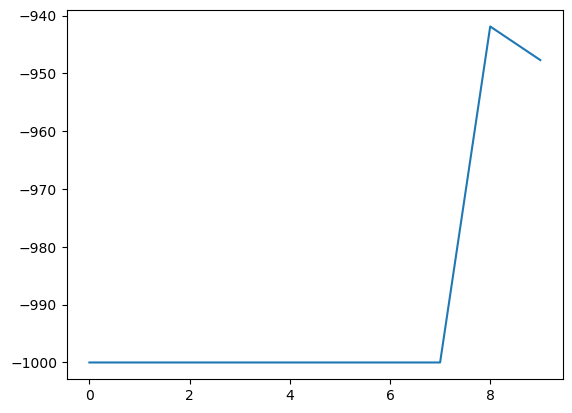

Number of successes: 1
Percentage of success: 10.0 %


In [3]:
run(10, is_training=True, render=False, save_to='mountain_car10')

/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car10.pkl
0.0%
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%


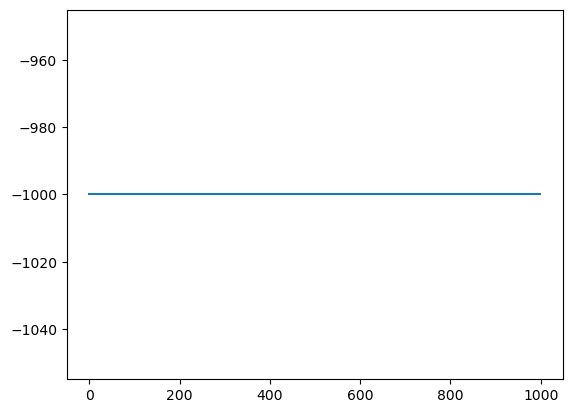

Number of successes: 0
Percentage of success: 0.0 %


In [4]:
run(1000, is_training=False, render=False, read_from='mountain_car10')

In [5]:
run(1, is_training=False, render=True, read_from='mountain_car10')

/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car10.pkl
Number of successes: 0
Percentage of success: 0.0 %


0.0%
40.0%
80.0%


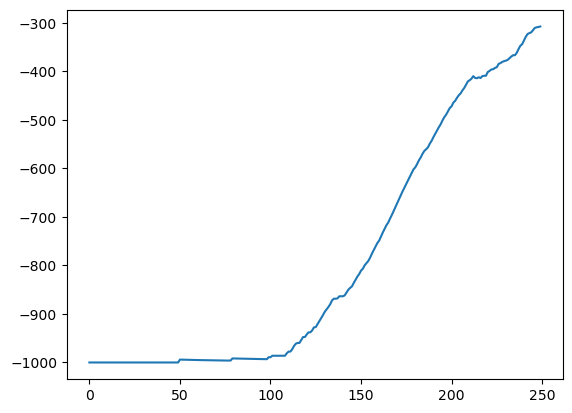

Number of successes: 139
Percentage of success: 55.60000000000001 %
/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car250.pkl
0.0%
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%


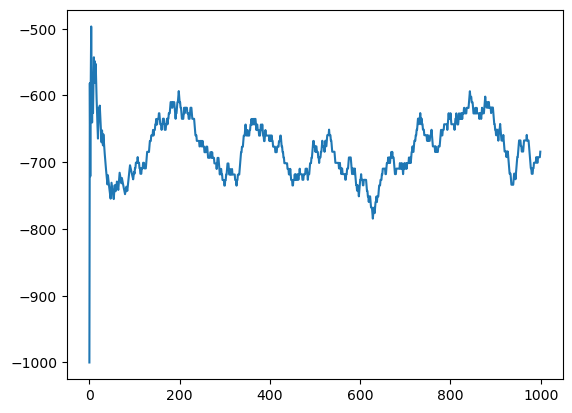

Number of successes: 381
Percentage of success: 38.1 %


In [6]:
run(250, is_training=True, render=False, save_to='mountain_car250')
run(1000, is_training=False, render=False, read_from='mountain_car250')

0.0%
13.333333333333334%
26.666666666666668%
40.0%
53.333333333333336%
66.66666666666666%
80.0%
93.33333333333333%


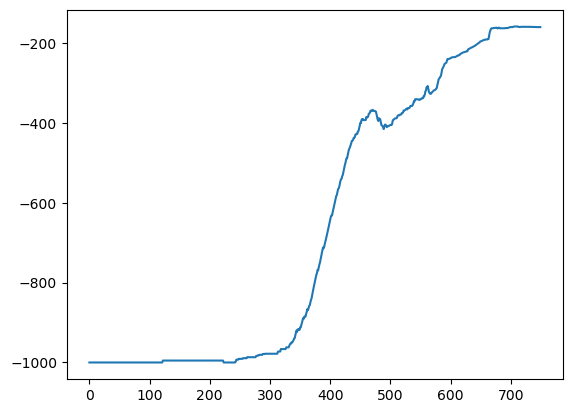

Number of successes: 412
Percentage of success: 54.93333333333334 %
/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car750.pkl
0.0%
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%


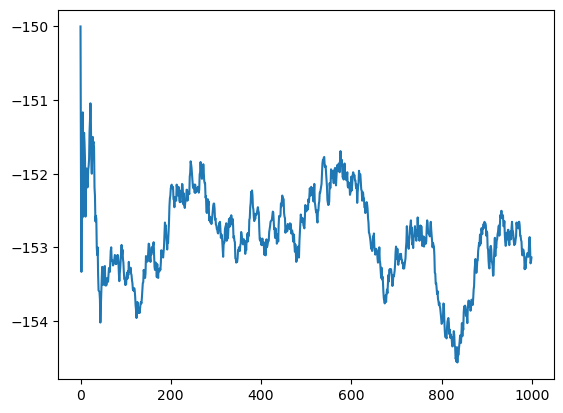

Number of successes: 1000
Percentage of success: 100.0 %


In [7]:
run(750, is_training=True, render=False, save_to='mountain_car750')
run(1000, is_training=False, render=False, read_from='mountain_car750')

0.0%
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%


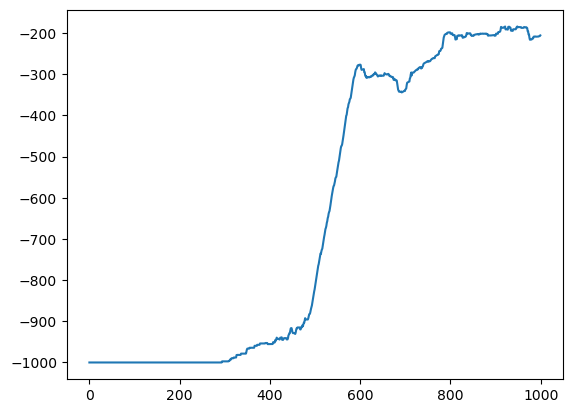

Number of successes: 555
Percentage of success: 55.50000000000001 %


In [8]:
run(1000, is_training=True, render=False, save_to='mountain_car1k')

/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car1k.pkl
0.0%
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%


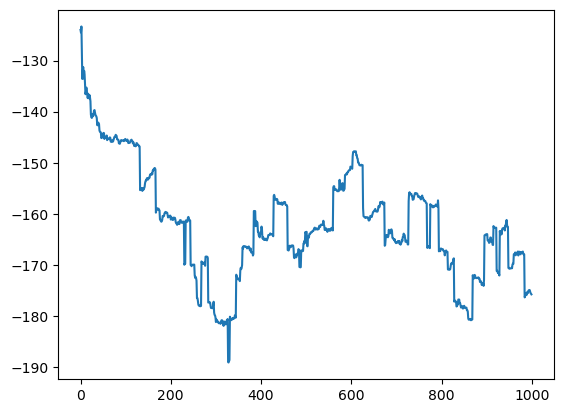

Number of successes: 985
Percentage of success: 98.5 %


In [9]:
run(1000, is_training=False, render=False, read_from='mountain_car1k')

In [5]:
run(1, is_training=False, render=False, read_from='mountain_car100k')

/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car100k.pkl
Number of successes: 1
Percentage of success: 100.0 %


In [6]:
run(1, is_training=False, render=True, read_from='mountain_car100k')

/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car100k.pkl
Number of successes: 1
Percentage of success: 100.0 %


/Users/davemag9/VSCode/Machine Learning/lab3/mountain_car100k.pkl


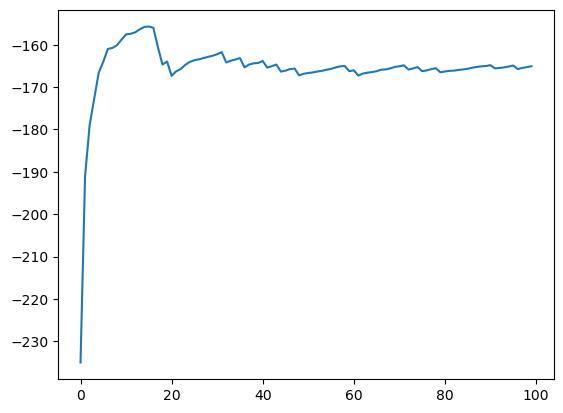

Number of successes: 100
Percentage of success: 100.0 %


In [7]:
run(100, is_training=False, render=False, read_from='mountain_car100k')

Висновок: натренована модель має точність 100% для подальших епізодів. Можемо сказати, що гру з машинкою пройдено. Перемога!!